# 03 · Hypothesis testing: is a supplier's talent flow really unbalanced?

Most companies replace departures with new hires, so small differences between hires and departures are part of normal turnover. A **large** difference can show how well a supplier attracts and keeps talent. A statistical test separates real differences from random variation.

For each supplier, the departures and hires per counterparty company are compared:

- **H0:** there is no real difference between departures and hires (*departures = hires*)
- **H1:** there is a real difference (*departures ≠ hires*)

Significance level: **α = 0.025** (stricter than the usual 0.05, to reduce false positives when 41 suppliers are tested).

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import ttest_ind, wilcoxon

warnings.filterwarnings("ignore", category=RuntimeWarning)
GREY, BLUE, RED = "#B3B3B3", "#7089AC", "#9E2A2B"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
ALPHA = 0.025

df = pd.read_csv("../data/processed/company_movements.csv")

## 1. Independent two-sample t-test per supplier

For each supplier the departures and hires across its counterparties are compared with `scipy.stats.ttest_ind`.

In [2]:
rows = []
for supplier, g in df.groupby("supplier"):
    t_stat, p_value = ttest_ind(g["departures"], g["hires"])
    rows.append({"supplier": supplier, "counterparties": len(g),
                 "departures": g["departures"].sum(), "hires": g["hires"].sum(),
                 "t": t_stat, "p_value": p_value})

results = pd.DataFrame(rows).set_index("supplier")
results["significant"] = results["p_value"] < ALPHA
results["result"] = np.select(
    [~results["significant"], results["hires"] > results["departures"]],
    ["No real difference", "Gains talent"], "Loses talent")

results.sort_values("p_value").round({"t": 2, "p_value": 4})

,counterparties,departures,hires,t,p_value,significant,result
supplier,,,,,,,
S16,6,0,6,-inf,0.0000,True,Gains talent
S03,51,7,50,-9.76,0.0000,True,Gains talent
S26,65,95,4,8.77,0.0000,True,Loses talent
S20,100,28,146,-7.30,0.0000,True,Gains talent
S25,100,42,110,-5.77,0.0000,True,Gains talent
S01,100,46,121,-5.48,0.0000,True,Gains talent
S31,100,47,104,-4.81,0.0000,True,Gains talent
S35,41,14,36,-4.14,0.0001,True,Gains talent
S29,21,4,21,-4.25,0.0001,True,Gains talent


In [3]:
summary = results["result"].value_counts().reindex(["Gains talent", "Loses talent", "No real difference"])
summary

result
Gains talent          11
Loses talent           5
No real difference    25
Name: count, dtype: int64

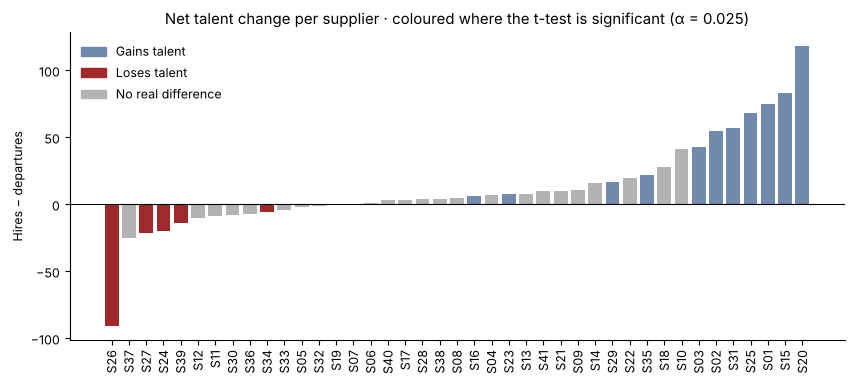

In [4]:
plot = results.assign(net=results["hires"] - results["departures"]).sort_values("net")
colors = np.where(~plot["significant"], GREY, np.where(plot["net"] > 0, BLUE, RED))

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(plot.index, plot["net"], color=colors)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title(f"Net talent change per supplier · coloured where the t-test is significant (α = {ALPHA})")
ax.set_ylabel("Hires − departures")
ax.tick_params(axis="x", rotation=90)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in (BLUE, RED, GREY)]
ax.legend(handles, ["Gains talent", "Loses talent", "No real difference"], frameon=False)
plt.show()

## 2. Robustness check: paired test

*Added when revisiting the project (2026).* Departures and hires for a supplier are measured against **the same** counterparty companies, so the two samples are paired rather than independent. The counts are also small and far from normally distributed (notebook 01). A **Wilcoxon signed-rank test** on the paired differences fits these conditions better, so it is used to check whether the conclusions hold.

In [5]:
def paired_p(g):
    diff = g["hires"] - g["departures"]
    if (diff != 0).sum() < 1:
        return np.nan
    return wilcoxon(g["hires"], g["departures"]).pvalue

results["p_wilcoxon"] = df.groupby("supplier").apply(paired_p, include_groups=False)
results["significant_wilcoxon"] = results["p_wilcoxon"] < ALPHA

agree = (results["significant"] == results["significant_wilcoxon"]).sum()
print(f"Both tests agree for {agree} of {len(results)} suppliers.")
print(f"Significant with t-test: {results['significant'].sum()} · with Wilcoxon: {results['significant_wilcoxon'].sum()}")

Both tests agree for 33 of 41 suppliers.
Significant with t-test: 16 · with Wilcoxon: 16


In [6]:
print("Suppliers where the two tests disagree")
(results.loc[results["significant"] != results["significant_wilcoxon"],
             ["counterparties", "departures", "hires", "p_value", "p_wilcoxon"]]
        .sort_values("counterparties").round(4))

Suppliers where the two tests disagree


,counterparties,departures,hires,p_value,p_wilcoxon
supplier,,,,,
S16,6,0,6,0.0000,0.0312
S34,8,7,1,0.0008,0.0703
S23,21,7,15,0.0233,0.1025
S39,48,35,21,0.0218,0.0891
S14,61,36,52,0.1705,0.0208
S10,100,84,125,0.0352,0.0052
S18,100,57,85,0.0335,0.0040
S22,129,120,140,0.4635,0.0051


## Conclusions

- With the t-test, **16 of 41 suppliers** show a real imbalance between hires and departures: **11 gain talent and 5 lose talent**, led by S26 (95 departures, 4 hires).
- The paired Wilcoxon test also finds 16 significant suppliers, and the two tests agree for **33 of 41**.
- They disagree for 8 suppliers, for two different reasons:
  - **Very few counterparties** (S16 with 6, S34 with 8): the t-test is unreliable here. S16 has no departures at all, so its t-statistic is infinite.
  - **Large suppliers with many small movements** (S10, S14, S18, S22): only the paired test finds a difference, because it compares each counterparty with itself and removes the variation between counterparties.
- In practice: a supplier marked *Loses talent* by both tests is a signal to look closer at retention before relying on it for long assignments, while *Gains talent* suppliers attract people from the market. For future runs, the paired test is the better default for this data.